# Seminário 5 — Comparação didática de runtimes em CPU

**Objetivo:** executar a mesma CNN em PyTorch, ONNX Runtime (sem/com otimizações de grafo) e OpenVINO, verificar equivalência numérica e medir a latência local.

O modelo tem **pesos aleatórios fixos**. Não é um classificador treinado: suas saídas são usadas apenas para validar a conversão. Não se mede acurácia nem se reproduzem os resultados dos artigos. TensorRT, LiteRT e energia são discutidos ao final.

Execute as células na ordem. Instale antes as dependências de `requirements.txt` no kernel selecionado. A execução não baixa datasets ou checkpoints. Resultados são gravados em `outputs/`.

## 1. Ambiente e controle de threads

Todas as execuções usam **CPU**, lote 1 e uma thread por runtime. A precisão de inferência do OpenVINO é configurada como FP32, evitando que uma preferência interna por BF16 torne a comparação silenciosamente diferente. As APIs e versões efetivas são registradas junto aos resultados.

In [1]:
import os
import tempfile
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ.setdefault("MPLCONFIGDIR", tempfile.mkdtemp(prefix="seminar5-mpl-"))

import json
import platform
import sys
import time
from collections import Counter
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import torch
from torch import nn
import onnx
from onnx import helper, numpy_helper, TensorProto
import onnxruntime as ort
import openvino as ov
import matplotlib.pyplot as plt
from IPython.display import display

torch.set_num_threads(1)
if torch.get_num_interop_threads() != 1:
    torch.set_num_interop_threads(1)
torch.manual_seed(558)
rng = np.random.default_rng(558)
out = Path("outputs")
out.mkdir(exist_ok=True)
cpu_name = platform.processor() or platform.machine()
if Path("/proc/cpuinfo").exists():
    cpu_name = next((l.split(":", 1)[1].strip() for l in Path("/proc/cpuinfo").read_text().splitlines()
                     if l.startswith("model name")), cpu_name)
environment = {
    "python": sys.version.split()[0], "platform": platform.platform(),
    "cpu": cpu_name, "logical_cpus": os.cpu_count(), "threads_per_runtime": 1,
    "packages": {p: version(p) for p in ["torch", "numpy", "onnx", "onnxruntime", "openvino"]},
    "onnxruntime_available_providers": ort.get_available_providers(),
}
print(json.dumps(environment, indent=2, ensure_ascii=False))

{
  "python": "3.13.12",
  "platform": "Linux-7.0.0-38-generic-x86_64-with-glibc2.39",
  "cpu": "Intel(R) Core(TM) Ultra 9 185H",
  "logical_cpus": 22,
  "threads_per_runtime": 1,
  "packages": {
    "torch": "2.15.0+cpu",
    "numpy": "2.5.4",
    "onnx": "1.23.2",
    "onnxruntime": "1.31.1",
    "openvino": "2026.4.1"
  },
  "onnxruntime_available_providers": [
    "AzureExecutionProvider",
    "CPUExecutionProvider"
  ]
}


## 2. Modelo e representação ONNX

Fluxo: **Conv → ReLU → Conv → ReLU → média espacial → camada linear**.

Para deixar a representação visível e evitar dependências extras do exportador PyTorch, o grafo ONNX é construído explicitamente com `onnx.helper` a partir dos **mesmos pesos** do modelo PyTorch. Isso ilustra a exportação de uma arquitetura conhecida, sem implementar um exportador genérico. A validação a seguir verifica a correspondência das duas descrições.

In [2]:
model = nn.Sequential(
    nn.Conv2d(3, 8, 3, padding=1), nn.ReLU(),
    nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(),
    nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(16, 10),
).eval()

weights = []
for layer_index, prefix in [(0, "conv1"), (2, "conv2"), (6, "fc")]:
    layer = model[layer_index]
    weights.extend([
        numpy_helper.from_array(layer.weight.detach().numpy(), prefix + "_w"),
        numpy_helper.from_array(layer.bias.detach().numpy(), prefix + "_b"),
    ])
nodes = [
    helper.make_node("Conv", ["input", "conv1_w", "conv1_b"], ["c1"], pads=[1, 1, 1, 1]),
    helper.make_node("Relu", ["c1"], ["r1"]),
    helper.make_node("Conv", ["r1", "conv2_w", "conv2_b"], ["c2"], pads=[1, 1, 1, 1]),
    helper.make_node("Relu", ["c2"], ["r2"]),
    helper.make_node("GlobalAveragePool", ["r2"], ["pool"]),
    helper.make_node("Flatten", ["pool"], ["flat"], axis=1),
    helper.make_node("Gemm", ["flat", "fc_w", "fc_b"], ["output"], transB=1),
]
graph = helper.make_graph(nodes, "seminar5_cnn",
    [helper.make_tensor_value_info("input", TensorProto.FLOAT, [1, 3, 64, 64])],
    [helper.make_tensor_value_info("output", TensorProto.FLOAT, [1, 10])], weights)
exported = helper.make_model(graph, opset_imports=[helper.make_opsetid("", 17)])
exported.ir_version = 9
onnx.checker.check_model(exported)
model_path = out / "cnn.onnx"
onnx.save(exported, model_path)
print("Parâmetros:", sum(p.numel() for p in model.parameters()))
print("Operadores ONNX:", dict(Counter(n.op_type for n in exported.graph.node)))
print("Arquivo:", model_path, "|", model_path.stat().st_size, "bytes")

Parâmetros: 1562
Operadores ONNX: {'Conv': 2, 'Relu': 2, 'GlobalAveragePool': 1, 'Flatten': 1, 'Gemm': 1}
Arquivo: outputs/cnn.onnx | 6705 bytes


## 3. Preparação dos runtimes

Medimos a criação de sessões/compilação separadamente. Essa primeira medição pode incluir caches e inicializações diferentes e não constitui uma comparação rigorosa de cold start.

Otimizações do ONNX Runtime podem criar nós específicos do provider. Menos nós não garantem menor tempo, e nós de reordenação podem aumentar a contagem. OpenVINO usa explicitamente o dispositivo `CPU`.

In [3]:
setup_ms = {}
sessions = {}
for label, level in [
    ("ORT sem otimizações", ort.GraphOptimizationLevel.ORT_DISABLE_ALL),
    ("ORT otimizado", ort.GraphOptimizationLevel.ORT_ENABLE_ALL),
]:
    options = ort.SessionOptions()
    options.intra_op_num_threads = 1
    options.inter_op_num_threads = 1
    options.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    options.graph_optimization_level = level
    options.optimized_model_filepath = str(out / ("ort_none.onnx" if "sem" in label else "ort_all.onnx"))
    start = time.perf_counter_ns()
    sessions[label] = ort.InferenceSession(str(model_path), options, providers=["CPUExecutionProvider"])
    setup_ms[label] = (time.perf_counter_ns() - start) / 1e6
    assert sessions[label].get_providers() == ["CPUExecutionProvider"]

start = time.perf_counter_ns()
core = ov.Core()
ov_model = core.read_model(model_path)
compiled = core.compile_model(ov_model, "CPU", {
    "INFERENCE_NUM_THREADS": 1, "NUM_STREAMS": 1,
    "PERFORMANCE_HINT": "LATENCY", "INFERENCE_PRECISION_HINT": "f32",
})
request = compiled.create_infer_request()
setup_ms["OpenVINO FP32"] = (time.perf_counter_ns() - start) / 1e6
print("Preparação medida uma vez (ms):", setup_ms)
print("OpenVINO — dispositivo:", compiled.get_property("EXECUTION_DEVICES"))
print("OpenVINO — precisão preferida:", compiled.get_property("INFERENCE_PRECISION_HINT"))
for file in ["ort_none.onnx", "ort_all.onnx"]:
    graph = onnx.load(out / file).graph
    print(file, dict(Counter((n.domain + ":" if n.domain else "") + n.op_type for n in graph.node)))

Preparação medida uma vez (ms): {'ORT sem otimizações': 2.613728, 'ORT otimizado': 0.984422, 'OpenVINO FP32': 38.080548}
OpenVINO — dispositivo: ['CPU']
OpenVINO — precisão preferida: <Type: 'float32'>
ort_none.onnx {'Conv': 2, 'Relu': 2, 'GlobalAveragePool': 1, 'Flatten': 1, 'Gemm': 1}
ort_all.onnx {'com.microsoft.nchwc:Conv': 2, 'com.microsoft.nchwc:GlobalAveragePool': 1, 'com.microsoft.nchwc:ReorderOutput': 1, 'Flatten': 1, 'Gemm': 1}


2026-10-30 13:31:47.371821298 [W:onnxruntime:, inference_session.cc:3240 operator()] Serializing optimized model with Graph Optimization level greater than ORT_ENABLE_EXTENDED and the NchwcTransformer enabled. The generated model may contain hardware specific optimizations, and should only be used in the same environment the model was optimized in.


## 4. Verificar antes de medir

As 12 entradas variam de valores positivos e negativos a zeros, uns e uma imagem esparsa. Cada caminho deve concordar com o PyTorch dentro da tolerância FP32 definida. Isso verifica **essas entradas**, sem constituir uma prova formal ou uma avaliação de acurácia.

Todos os caminhos recebem arrays NumPy residentes na CPU e devolvem arrays NumPy. A medição inclui o wrapper Python de cada API e a disponibilização da saída no host; não é uma temporização isolada de kernels.

In [4]:
@torch.inference_mode()
def run_torch(x):
    return model(torch.from_numpy(x)).numpy()

def run_ort_none(x):
    return sessions["ORT sem otimizações"].run(None, {"input": x})[0]

def run_ort_all(x):
    return sessions["ORT otimizado"].run(None, {"input": x})[0]

def run_openvino(x):
    request.infer({0: x})
    return request.get_output_tensor(0).data.copy()

runners = {"PyTorch FP32": run_torch, "ORT sem otimizações": run_ort_none,
           "ORT otimizado": run_ort_all, "OpenVINO FP32": run_openvino}
shape = (1, 3, 64, 64)
test_inputs = [rng.normal(0, scale, shape).astype(np.float32) for scale in [0.1, 1.0, 3.0] for _ in range(3)]
test_inputs.extend([np.zeros(shape, np.float32), np.ones(shape, np.float32)])
sparse = np.zeros(shape, np.float32)
sparse[0, 1, 32, 32] = 1
test_inputs.append(sparse)
assert len(test_inputs) == 12
max_errors = {name: 0.0 for name in runners}
for x in test_inputs:
    reference = run_torch(x)
    for name, run in runners.items():
        actual = run(x)
        assert actual.shape == reference.shape and np.isfinite(actual).all()
        np.testing.assert_allclose(actual, reference, rtol=1e-4, atol=1e-5, err_msg=name)
        max_errors[name] = max(max_errors[name], float(np.max(np.abs(actual - reference))))
print("Equivalência verificada em", len(test_inputs), "entradas.")
print("Maior erro absoluto por caminho:", max_errors)

Equivalência verificada em 12 entradas.
Maior erro absoluto por caminho: {'PyTorch FP32': 0.0, 'ORT sem otimizações': 5.513429641723633e-07, 'ORT otimizado': 2.115964889526367e-06, 'OpenVINO FP32': 4.470348358154297e-08}


## 5. Medição em regime estável

São 50 aquecimentos por caminho e **três rodadas de 200 chamadas**. A ordem dos runtimes é embaralhada em cada rodada para reduzir um viés fixo de ordem. A mesma entrada já alocada é reutilizada. Carga, compilação, geração de entradas e validação ficam fora da medição. O loop é serial e as APIs de CPU são síncronas.

Cada estatística agrupa 600 chamadas da mesma sessão. p95 é um percentil empírico, sem intervalo de confiança. Os resultados não estimam latência em GPU, tempo de aplicação com imagem/vídeo, energia ou comportamento de um modelo grande.

In [5]:
WARMUP, REPEATS, ROUNDS = 50, 200, 3
x = rng.normal(size=shape).astype(np.float32)
for run in runners.values():
    for _ in range(WARMUP):
        run(x)
samples = {name: [] for name in runners}
round_order = []
for round_index in range(ROUNDS):
    order = list(runners)
    rng.shuffle(order)
    round_order.append(order)
    for name in order:
        run = runners[name]
        for _ in range(REPEATS):
            start = time.perf_counter_ns()
            result = run(x)
            samples[name].append((time.perf_counter_ns() - start) / 1e6)

rows = []
for name, values in samples.items():
    a = np.asarray(values)
    rows.append({"runtime": name, "mean_ms": float(a.mean()),
                 "std_ms": float(a.std(ddof=1)), "p50_ms": float(np.median(a)),
                 "p95_ms": float(np.percentile(a, 95)), "calls": len(a),
                 "max_abs_error": max_errors[name]})
results = pd.DataFrame(rows)
baseline = results.loc[results.runtime == "PyTorch FP32", "mean_ms"].iloc[0]
results["speedup_vs_pytorch"] = baseline / results.mean_ms
display(results.round(6))
report = {"environment": environment, "precision": "FP32 configurado", "batch": 1,
          "input_shape": list(shape), "validation_inputs": len(test_inputs),
          "warmup": WARMUP, "repeats_per_round": REPEATS, "rounds": ROUNDS,
          "round_order": round_order, "setup_ms_once": setup_ms,
          "scope": "API síncrona CPU: NumPy de entrada até NumPy de saída, sem pré/pós-processamento",
          "results": results.to_dict(orient="records")}
(out / "benchmark.json").write_text(json.dumps(report, indent=2, ensure_ascii=False))
results.to_csv(out / "benchmark.csv", index=False)
assert all(results.calls == REPEATS * ROUNDS)
assert (results.mean_ms > 0).all()
print("Resultados locais gravados em", out.resolve())

,runtime,mean_ms,std_ms,p50_ms,p95_ms,calls,max_abs_error,speedup_vs_pytorch
0,PyTorch FP32,0.298474,0.035613,0.291099,0.347013,600,0.000000,1.000000
1,ORT sem otimizações,0.246276,0.010272,0.244394,0.263541,600,0.000001,1.211950
2,ORT otimizado,0.167075,0.007256,0.165549,0.178742,600,0.000002,1.786462
3,OpenVINO FP32,0.202974,0.019459,0.200433,0.212488,600,0.000000,1.470499


Resultados locais gravados em /home/ribeiro.alvaro/Documentos/Mestrado/Repositories/alvaro-ribeiro-985-tp558/seminar5/notebooks/outputs


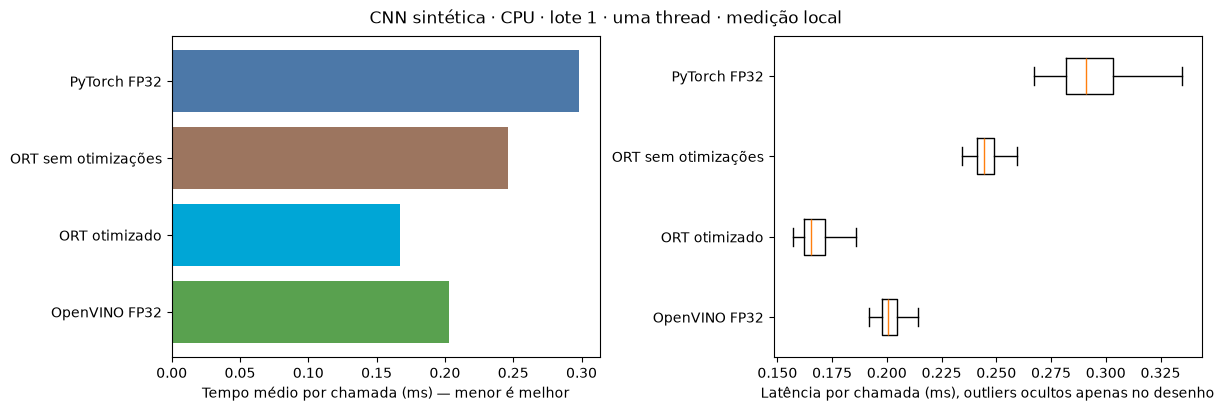

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
labels = results.runtime.tolist()
axes[0].barh(labels, results.mean_ms, color=["#4c78a8", "#9c755f", "#00a6d6", "#59a14f"])
axes[0].set_xlabel("Tempo médio por chamada (ms) — menor é melhor")
axes[0].invert_yaxis()
axes[1].boxplot([samples[n] for n in labels], tick_labels=labels, orientation="horizontal", showfliers=False)
axes[1].set_xlabel("Latência por chamada (ms), outliers ocultos apenas no desenho")
axes[1].invert_yaxis()
fig.suptitle("CNN sintética · CPU · lote 1 · uma thread · medição local")
fig.savefig(out / "latency.png", dpi=150)
plt.show()

## 6. Como interpretar

1. Verifique primeiro o erro numérico. Tempo menor com semântica diferente não constitui uma comparação válida.
2. Compare ONNX Runtime sem/com otimização no mesmo provider. A mudança no grafo explica uma possibilidade de aceleração, não uma garantia.
3. Compare média e p95. Uma média baixa pode esconder chamadas lentas.
4. Reexecute em sessões independentes, altere o tamanho de entrada ou use um modelo treinado. Os resultados desta CNN pequena podem ser dominados pelo overhead da API.
5. Não confunda compilação com inferência ou extrapole CPU para GPU.

### Extensão para TensorRT e LiteRT

**TensorRT:** requer GPU NVIDIA e pilha compatível. Construa o engine no ambiente-alvo, valide suas saídas, separe a compilação, aqueça e sincronize CUDA. Declare se transferências CPU–GPU estão incluídas. Um provider TensorRT no ONNX Runtime e um engine TensorRT executado diretamente são dois caminhos de integração distintos.

**LiteRT:** converta o modelo por um caminho suportado e informe a API/delegate, o dispositivo e a precisão usados. Verifique operadores não acelerados e fallback. Para INT8, use dados representativos na calibração quando exigidos. Avalie a métrica de tarefa antes e depois. Os resultados históricos de TFLite não representam automaticamente o LiteRT atual.

**Energia:** é necessário instrumentar a plataforma e integrar potência no mesmo intervalo da execução. Este notebook não estima watts a partir de tempo de CPU.

### Relação com os artigos

- [Suchý e Turčaník (2026)](https://www.nature.com/articles/s41598-026-46453-6): diferencia latência da rede, FPS de vídeo e energia. Nenhum caso atinge 25 FPS.
- [Ratul et al. (2025)](https://www.mdpi.com/2079-9292/14/15/2977): compara também memória, potência e throughput com lotes variáveis. A Tabela 6 contém uma exceção VGG16/PyTorch à predominância do TensorRT.
- [Gomez Fernandez et al. (2026), v1](https://arxiv.org/html/2607.11356v1): lote 1 e apenas tempo da rede. Grounding DINO mostra que o ranking muda com arquitetura e hardware.

Documentação: [ONNX](https://onnx.ai/onnx/), [ONNX Runtime](https://onnxruntime.ai/docs/), [OpenVINO](https://docs.openvino.ai/), [TensorRT](https://docs.nvidia.com/deeplearning/tensorrt/latest/), [LiteRT](https://developers.google.com/edge/litert).